# Modelling

Recommendation System, compare two retrieval methods:
- TF-IDF
- Vector cosine similarity

## Retrieval Setup

### 1. Read Data

We read the cases built in `cleaning2.ipynb` and the tweets from `cleaned_df.pkl`. The tweets are needed to find each customer's first tweet now, and to show the full conversation of a case later.

**Why we only search first questions**

- The goal of RQ3: when a customer asks a new question, we find similar past cases and show how support handled them.
- A new question is always the start of a conversation, so the library should also hold conversation starts. This way we compare like with like.
- The first question usually describes the problem on its own, for example "my battery drains fast after iOS 11".
- Later tweets such as "still waiting" or "thanks" depend on earlier tweets. They would match many unrelated cases.
- We do not lose the later tweets: when we show a matched case, we show its whole conversation.

**Two filters**

- `is_first_tweet == True`: the tweet does not reply to another tweet.
- The tweet is the customer's earliest tweet in the data. Some customers send a new tweet instead of replying, to follow up on an old problem (for example "Just to be clear.. I have been home ALL day!"). These tweets pass the first filter but are not new questions.
- Limits: the data starts on Oct 4, so we cannot see conversations before that. A customer who asks a different question weeks later is also removed.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the cases and all tweets (tweets are used to find first tweets and full conversations)
cases = pd.read_pickle("../data/cases.pkl")
tweets = pd.read_pickle("../data/cleaned_df.pkl")
# Turn the time text into UTC datetime
tweets["created_at"] = pd.to_datetime(tweets["created_at"], format="%a %b %d %H:%M:%S %z %Y", utc=True)
print("All cases:", cases.shape[0])
# Keep tweets that do not reply to another tweet
cases = cases[cases["is_first_tweet"]].copy()
print("First-tweet cases:", cases.shape[0])

All cases: 209868
First-tweet cases: 127617


Cases that are the customer's first tweet: 110816


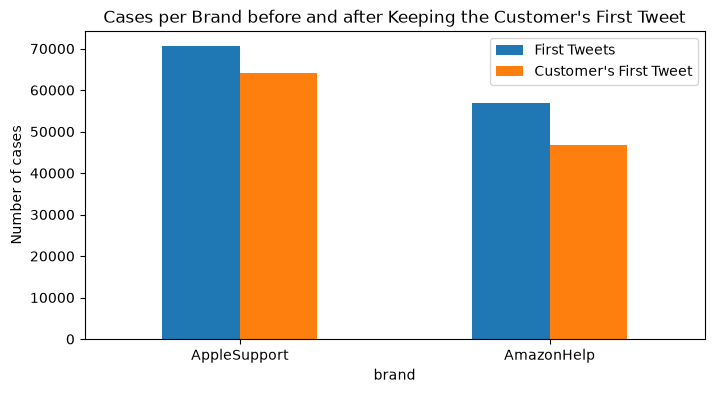

,First Tweets,Customer's First Tweet
brand,,
AppleSupport,70701,64031
AmazonHelp,56916,46785


In [2]:
before = cases["brand"].value_counts()
# Find each customer's earliest tweet time, keep the case only if it is that tweet
customer_first_time = tweets[tweets["inbound"] == True].groupby("author_id")["created_at"].min()
cases = cases[cases["created_at"] == cases["customer_id"].map(customer_first_time)].copy()
print("Cases that are the customer's first tweet:", cases.shape[0])

# Compare the number of cases per brand before and after
brand_counts = pd.DataFrame({"First Tweets": before, "Customer's First Tweet": cases["brand"].value_counts()})
brand_counts.plot(kind="bar", figsize=(8, 4), rot=0)
plt.ylabel("Number of cases")
plt.title("Cases per Brand before and after Keeping the Customer's First Tweet")
plt.show()
brand_counts

### 2. Clean Text

We make a new column `clean_text` for retrieval and keep the original `customer_text` for display.

- Turn HTML entities back into symbols: `&amp;`, `&lt;`, `&gt;` become `&`, `<`, `>`.
- Remove `@` mentions such as `@AppleSupport` or `@115821`. They do not describe the problem and would make tweets to the same brand look similar.
- Remove links.
- Change to lowercase and join extra spaces and line breaks into one space.
- We keep punctuation, stop words and emojis, because the embedding model works best on full sentences.

After cleaning, we remove texts with 3 words or fewer, such as "fix this" or "what the heck". They do not say what the problem is, so they cannot be matched to useful cases.

In [3]:
# Turn HTML entities back into symbols
cases["clean_text"] = cases["customer_text"].str.replace("&amp;", "&").str.replace("&lt;", "<").str.replace("&gt;", ">")
# Remove @ mentions and links
cases["clean_text"] = cases["clean_text"].str.replace(r"@\w+", " ", regex=True).str.replace(r"https?://\S+", " ", regex=True)
# Lowercase and join extra spaces
cases["clean_text"] = cases["clean_text"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
cases[["customer_text", "clean_text"]].head()

,customer_text,clean_text
2,Apple Podcast is not played continuously on #i...,apple podcast is not played continuously on #i...
5,@AppleSupport since I updated to the most curr...,since i updated to the most current update the...
6,@AppleSupport my iPhone used to work fine with...,my iphone used to work fine with my bmw idrive...
7,@AppleSupport will there be a fix for the poor...,will there be a fix for the poor #batterylife ...
8,@AppleSupport song previews aren’t playing on ...,song previews aren’t playing on itunes store o...


In [4]:
# Count words and remove texts with 3 words or fewer
cases["word_count"] = cases["clean_text"].str.split().str.len()
print("Cases before removing short texts:", cases.shape[0])
cases = cases[cases["word_count"] > 3].copy()
print("Cases after removing short texts:", cases.shape[0])

Cases before removing short texts: 110816
Cases after removing short texts: 110022


### 3. Split Data

We split the cases by time, to copy how the system would be used in real life: past cases are used to answer new questions.

- `history`: cases before Nov 27, 2017. This is the library we search in.
- `query`: cases from Nov 27 to Dec 3, 2017 (the last 7 days). These are the "new questions".
- Splitting by time also makes sure a query never finds itself in the library.
- The history set covers the iOS bug and Black Friday periods, so these kinds of problems can be found.
- Nov 27 is Cyber Monday, so the query set has a few more Amazon tweets than usual.
- When we search, we only look at cases from the same brand as the query.

In [5]:
# The last 7 days are new questions (query), the rest is the library (history)
cases["set"] = np.where(cases["created_at"] >= "2017-11-27", "query", "history")
pd.DataFrame({"Number of Cases": cases.groupby(["set", "brand"]).size()})

Number of Cases
set     brand                        
history AmazonHelp              39162
        AppleSupport            58169
query   AmazonHelp               7372
        AppleSupport             5319

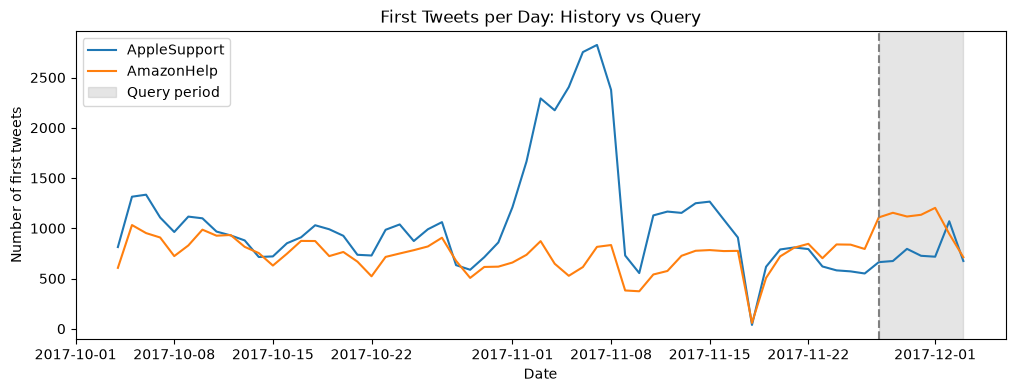

In [6]:
# First tweets per day for each brand, with the query period shaded
day_counts = cases.groupby([cases["created_at"].dt.date, "brand"]).size().unstack()
plt.figure(figsize=(12, 4))
plt.plot(day_counts.index, day_counts["AppleSupport"], label="AppleSupport")
plt.plot(day_counts.index, day_counts["AmazonHelp"], label="AmazonHelp")
plt.axvline(pd.Timestamp("2017-11-27"), color="gray", linestyle="--")
plt.axvspan(pd.Timestamp("2017-11-27"), pd.Timestamp("2017-12-03"), color="gray", alpha=0.2, label="Query period")
plt.xlabel("Date")
plt.ylabel("Number of first tweets")
plt.title("First Tweets per Day: History vs Query")
plt.legend()
plt.show()

### 4. Method A: TF-IDF

TF-IDF turns each tweet into a vector of word weights. A word gets a high weight when it appears in this tweet but is rare in the whole history set, so common words matter less and specific words (like "battery" or "refund") matter more.

- We fit TF-IDF on the history set only, then use it to transform the query set.
- `stop_words="english"` removes very common words such as "the", "is" and "my".
- `min_df=2` ignores words that appear only once, such as typos and order numbers.
- TF-IDF vectors already have length 1, so multiplying two vectors gives their cosine similarity.
- For each query, we only keep history cases from the same brand.

We first look at the top 5 matches for one example query, then check the best-match similarity for 1,000 sample queries. A formal comparison with the embedding method is in Section 6.

To see how support handled each match, we show its whole conversation with a small function `get_chain(case_id)`. It starts from the first tweet, keeps adding tweets that reply to any tweet already in the chain until no new tweet is found, then sorts them by time. We write it as a function because Section 5 uses it again.

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Split into history and query
history = cases[cases["set"] == "history"].reset_index(drop=True)
query = cases[cases["set"] == "query"].reset_index(drop=True)
# Fit TF-IDF on history only, then transform the queries
tfidf = TfidfVectorizer(stop_words="english", min_df=2)
history_tfidf = tfidf.fit_transform(history["clean_text"])
query_tfidf = tfidf.transform(query["clean_text"])
print("Vocabulary size:", len(tfidf.vocabulary_))
print("History matrix:", history_tfidf.shape)
print("Query matrix:", query_tfidf.shape)

Vocabulary size: 14450
History matrix: (97331, 14450)
Query matrix: (12691, 14450)


In [8]:
pd.set_option("display.max_colwidth", None)
# Pick one example query
example = query.sample(1, random_state=1007).index[0]
print("Brand:", query.loc[example, "brand"])
print("Query:", query.loc[example, "customer_text"])

# Cosine similarity with every history case; other brand gets -1 so it is never picked
scores = (history_tfidf @ query_tfidf[example].T).toarray().ravel()
scores[(history["brand"] != query.loc[example, "brand"]).to_numpy()] = -1
# Index of the 5 highest scores
top = np.argsort(scores)[::-1][:5]
pd.DataFrame({"Score": scores[top], "Case ID": history.loc[top, "case_id"], "History Tweet": history.loc[top, "customer_text"]})

Brand: AmazonHelp
Query: @116090 @amazonhelp Well, 2 weeks of waiting and no package. I've called both the shipping company and your help line, both have been unable to do anything and refer me to the other. PLEASE stop using #intelcom!!!


,Score,Case ID,History Tweet
84918,0.321978,2611579,"@AmazonHelp Placed an order for 2 day shipping (prime member) and the items have been ""out for delivery"" in the wrong city for 3 days. Please stop using Intelcom for deliveries."
45833,0.317164,2606680,@AmazonHelp Can you stop using Intelcom for your Canadian Prime deliveries? They're late and I've received no tracking information.
39690,0.306331,1279910,I’m sick of Amazon I’ve been waiting on my package for 2 weeks it better be here today
90183,0.301404,2799329,@116090 @AmazonHelp stop shipping with Intelcom. Turns into an insane hassle with no possible resolutions. Ridiculous. Never had an issue with delivery until Intelcom was assigned to deliver things.
60593,0.288863,1640913,"@AmazonHelp Will be dumping our Prime membership until you stop using Intelcom - have had 1 successful delivery, many lost pacakges"


In [9]:
# Collect a case and all tweets that reply to it (directly or later in the chain)
def get_chain(case_id):
    chain_ids = [case_id]
    while True:
        new_ids = tweets.loc[tweets["in_response_to_tweet_id"].isin(chain_ids) & ~tweets["tweet_id"].isin(chain_ids), "tweet_id"].tolist()
        if len(new_ids) == 0:
            break
        chain_ids = chain_ids + new_ids
    # Sort the conversation by time
    chain = tweets[tweets["tweet_id"].isin(chain_ids)].sort_values("created_at")
    return pd.DataFrame({"Time": chain["created_at"].dt.strftime("%Y-%m-%d %H:%M"), "Author": np.where(chain["inbound"], "Customer", chain["author_id"]), "Text": chain["text"]})

# Show the full conversation of each top-5 match
for rank, i in enumerate(top):
    print(f"Match {rank + 1}, score {scores[i]:.3f}")
    display(get_chain(history.loc[i, "case_id"]))

Match 1, score 0.322


,Time,Author,Text
2442289,2017-11-17 11:56,Customer,"@AmazonHelp Placed an order for 2 day shipping (prime member) and the items have been ""out for delivery"" in the wrong city for 3 days. Please stop using Intelcom for deliveries."
2442288,2017-11-17 12:06,AmazonHelp,@738467 I am very sorry to hear this David. Can I ask for you to reach out to us through the link below so we can see what options we have for you: https://t.co/hApLpMlfHN. ^GA


Match 2, score 0.317


,Time,Author,Text
2437477,2017-10-30 21:00,Customer,@AmazonHelp Can you stop using Intelcom for your Canadian Prime deliveries? They're late and I've received no tracking information.
2437471,2017-10-30 21:04,AmazonHelp,@737428 I'm sorry for the poor delivery experiences! Have we missed a recent delivery for an order you placed? ^ME
2437472,2017-10-30 21:07,Customer,"@AmazonHelp A day late on delivery, about to be 2. No up to date tracking info. No package. I'm wondering why you continue to use this courrier"
2437473,2017-10-30 21:25,AmazonHelp,"@737428 If you have a moment, please contact us directly by phone or chat so we can look into this with you: https://t.co/Q7Ftz6nj80 ^LH"
2437474,2017-10-30 21:48,Customer,@AmazonHelp I spoke to someone on the phone. I was given a promo code but it still doesn't really fix the underlying problem with Intelcom itself.
2437475,2017-10-30 23:36,AmazonHelp,@737428 I understand the frustration with a late order! Did the agent mention sending your feedback to our transportation team? ^TN
2437476,2017-10-30 23:39,Customer,@AmazonHelp Yeah she did. Whether or not they'll actually do anything with the complaint is anyone's guess.


Match 3, score 0.306


,Time,Author,Text
1158697,2017-10-26 16:37,Customer,I’m sick of Amazon I’ve been waiting on my package for 2 weeks it better be here today
1158696,2017-10-26 16:45,AmazonHelp,@419470 I'm sorry to hear we've let you down! Have we missed the delivery date shown in confirmation e-mail? What is the status? ^FR


Match 4, score 0.301


,Time,Author,Text
2626976,2017-11-21 23:44,Customer,@116090 @AmazonHelp stop shipping with Intelcom. Turns into an insane hassle with no possible resolutions. Ridiculous. Never had an issue with delivery until Intelcom was assigned to deliver things.
2626975,2017-11-21 23:48,AmazonHelp,"@781015 I'm so sorry to hear this. If you have a moment, please reach us here: https://t.co/Q7Ftz6ETZy so we can submit a carrier's feedback on your behalf. ^LH"


Match 5, score 0.289


,Time,Author,Text
1494601,2017-11-05 23:24,Customer,"@AmazonHelp Will be dumping our Prime membership until you stop using Intelcom - have had 1 successful delivery, many lost pacakges"
1494599,2017-11-05 23:55,AmazonHelp,@501652 I'm sorry to hear this! Are you currently waiting on the delivery of a late package? ^BH
1494600,2017-11-06 00:00,Customer,"@AmazonHelp Item showing as delivered and was refunded already. But this is the 4th/5th time that Intelcom has ""delivered"" an item that never arrived"


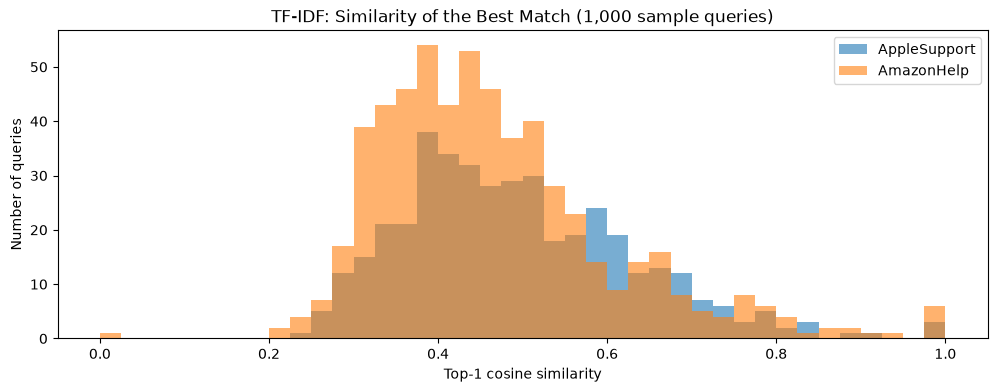

,count,mean,std,min,25%,50%,75%,max
brand,,,,,,,,
AmazonHelp,584.0,0.467082,0.141206,0.000000,0.367797,0.441375,0.530206,1.0
AppleSupport,416.0,0.496510,0.139874,0.229057,0.394541,0.476872,0.580237,1.0


In [10]:
# For 1,000 sample queries, record the best score within the same brand
sample = query.sample(1000, random_state=1007)
top1 = []
for i in sample.index:
    scores = (history_tfidf @ query_tfidf[i].T).toarray().ravel()
    top1.append(scores[(history["brand"] == query.loc[i, "brand"]).to_numpy()].max())
sample["tfidf_top1"] = top1

# Histogram of the best score for each brand
plt.figure(figsize=(12, 4))
plt.hist(sample.loc[sample["brand"] == "AppleSupport", "tfidf_top1"], bins=np.linspace(0, 1, 41), alpha=0.6, label="AppleSupport")
plt.hist(sample.loc[sample["brand"] == "AmazonHelp", "tfidf_top1"], bins=np.linspace(0, 1, 41), alpha=0.6, label="AmazonHelp")
plt.xlabel("Top-1 cosine similarity")
plt.ylabel("Number of queries")
plt.title("TF-IDF: Similarity of the Best Match (1,000 sample queries)")
plt.legend()
plt.show()
sample.groupby("brand")["tfidf_top1"].describe()

### 5. Method B: Embedding

An embedding model turns each tweet into a vector that represents its meaning, not just its words. For example, "package never arrived" and "didn't receive my order" share no words, so TF-IDF sees them as unrelated, but their embeddings are close.

- We use the sentence-transformers model `all-MiniLM-L6-v2`. It is small and widely used, and gives a 384-number vector for each tweet.
- We use the same `clean_text` as TF-IDF, so the comparison is fair.
- Encoding about 110,000 tweets takes a few minutes on CPU, so we save the vectors to `../data/*.npy` and load them next time. If the filtering steps above change, delete these files so they are made again.

We do the similarity part with NumPy:

- Normalize: divide each vector by its length (`np.linalg.norm`), so every vector has length 1. The dot product of two length-1 vectors is their cosine similarity, the same measure as in Section 4. This model already gives length-1 vectors, and the check below confirms it; we still normalize so the code is correct for any model.
- One query: `history_emb @ query_vector` gives the similarity to all history cases at once.
- Many queries: one matrix product per brand gives a full similarity table, and `.max(axis=1)` takes the best score of each row. No Python loop over queries is needed.

We use the same example query and the same 1,000 sample queries as Section 4. The scores of the two methods are on different scales, so we do not compare them directly here. The formal comparison is in Section 6.

In [11]:
import os
import time
from sentence_transformers import SentenceTransformer

# Encode once and save; later runs load the saved arrays
if os.path.exists("../data/history_emb.npy") and os.path.exists("../data/query_emb.npy"):
    history_emb = np.load("../data/history_emb.npy")
    query_emb = np.load("../data/query_emb.npy")
else:
    model = SentenceTransformer("all-MiniLM-L6-v2")
    start = time.time()
    history_emb = model.encode(history["clean_text"].tolist(), batch_size=256, show_progress_bar=True)
    query_emb = model.encode(query["clean_text"].tolist(), batch_size=256, show_progress_bar=True)
    print(f"Encoding time: {time.time() - start:.0f} seconds")
    np.save("../data/history_emb.npy", history_emb)
    np.save("../data/query_emb.npy", query_emb)

# Check the saved arrays still match the current data
print("Rows match history and query:", history_emb.shape[0] == len(history) and query_emb.shape[0] == len(query))

Rows match history and query: True


In [12]:
# Length of each vector (one number per row)
history_norm = np.linalg.norm(history_emb, axis=1, keepdims=True)
query_norm = np.linalg.norm(query_emb, axis=1, keepdims=True)
print("Vector lengths before normalizing (first 5):", history_norm[:5].ravel().round(3))

# Divide each row by its own length (broadcasting), so every vector has length 1
history_emb = history_emb / history_norm
query_emb = query_emb / query_norm
print("All lengths are 1:", np.allclose(np.linalg.norm(history_emb, axis=1), 1) and np.allclose(np.linalg.norm(query_emb, axis=1), 1))
print("History embeddings:", history_emb.shape, history_emb.dtype, f"{history_emb.nbytes / 1e6:.0f} MB")
print("Query embeddings:", query_emb.shape, query_emb.dtype, f"{query_emb.nbytes / 1e6:.0f} MB")

Vector lengths before normalizing (first 5): [1. 1. 1. 1. 1.]
All lengths are 1: True
History embeddings: (97331, 384) float32 150 MB
Query embeddings: (12691, 384) float32 19 MB


In [13]:
# Same example query as Section 4: dot product with every history vector
print("Query:", query.loc[example, "customer_text"])
emb_scores = history_emb @ query_emb[example]

# Other brand gets -1 so it is never picked, then take the 5 highest scores
same_brand = (history["brand"] == query.loc[example, "brand"]).to_numpy()
emb_scores[~same_brand] = -1
emb_top = np.argsort(emb_scores)[::-1][:5]
pd.DataFrame({"Score": emb_scores[emb_top], "Case ID": history.loc[emb_top, "case_id"], "History Tweet": history.loc[emb_top, "customer_text"]})

Query: @116090 @amazonhelp Well, 2 weeks of waiting and no package. I've called both the shipping company and your help line, both have been unable to do anything and refer me to the other. PLEASE stop using #intelcom!!!


,Score,Case ID,History Tweet
88692,0.798062,2753577,Is there any way to get something shipped from @116090 without using #intelcom? Still waiting for the 1day shipping I ordered on Thursday and their site gives no updates and no way to contact people on the phone...
71973,0.790825,2205311,Hi @116090. Please stop sending packages with *Intelcom express*. They failed to deliver your package and followed it up with terrible customer service :(.
84918,0.719627,2611579,"@AmazonHelp Placed an order for 2 day shipping (prime member) and the items have been ""out for delivery"" in the wrong city for 3 days. Please stop using Intelcom for deliveries."
90183,0.675058,2799329,@116090 @AmazonHelp stop shipping with Intelcom. Turns into an insane hassle with no possible resolutions. Ridiculous. Never had an issue with delivery until Intelcom was assigned to deliver things.
89921,0.668758,2792004,@AmazonHelp My package I ordered was estimated to be delivered Nov 9 2017 - Nov 11 2017. It's still not here! Shipping courier is Intelcom but my tracking number doesn't go through! Help!


In [14]:
# Show the full conversation of each top-5 match
for rank, i in enumerate(emb_top):
    print(f"Match {rank + 1}, score {emb_scores[i]:.3f}")
    display(get_chain(history.loc[i, "case_id"]))

Match 1, score 0.798


,Time,Author,Text
2582429,2017-11-21 01:43,Customer,Is there any way to get something shipped from @116090 without using #intelcom? Still waiting for the 1day shipping I ordered on Thursday and their site gives no updates and no way to contact people on the phone...
2582427,2017-11-21 01:47,AmazonHelp,"@770774 I'm very sorry you haven't received your order. Whenever you have the time, give us a shout here: https://t.co/Q7Ftz6ETZy We'd be happy to assist with your order in real-time. ^SK"
2582428,2017-11-21 01:59,Customer,"@AmazonHelp I've been in contact with you guys twice already. You guys have been as helpful as you can be, it's the courier that you use that isn't. You cannot get a hold of them and their tracking system doesn't work."


Match 2, score 0.791


,Time,Author,Text
2046618,2017-11-09 22:41,Customer,Hi @116090. Please stop sending packages with *Intelcom express*. They failed to deliver your package and followed it up with terrible customer service :(.
2046617,2017-11-09 22:44,AmazonHelp,"@644809 I'm so sorry to hear this, Ash! We like our customers to have a great experience with us, and it seems we've let you down! Without posting personal account information, tell us more about your situation.\n-Anita"


Match 3, score 0.720


,Time,Author,Text
2442289,2017-11-17 11:56,Customer,"@AmazonHelp Placed an order for 2 day shipping (prime member) and the items have been ""out for delivery"" in the wrong city for 3 days. Please stop using Intelcom for deliveries."
2442288,2017-11-17 12:06,AmazonHelp,@738467 I am very sorry to hear this David. Can I ask for you to reach out to us through the link below so we can see what options we have for you: https://t.co/hApLpMlfHN. ^GA


Match 4, score 0.675


,Time,Author,Text
2626976,2017-11-21 23:44,Customer,@116090 @AmazonHelp stop shipping with Intelcom. Turns into an insane hassle with no possible resolutions. Ridiculous. Never had an issue with delivery until Intelcom was assigned to deliver things.
2626975,2017-11-21 23:48,AmazonHelp,"@781015 I'm so sorry to hear this. If you have a moment, please reach us here: https://t.co/Q7Ftz6ETZy so we can submit a carrier's feedback on your behalf. ^LH"


Match 5, score 0.669


,Time,Author,Text
2619689,2017-11-21 20:30,Customer,@AmazonHelp My package I ordered was estimated to be delivered Nov 9 2017 - Nov 11 2017. It's still not here! Shipping courier is Intelcom but my tracking number doesn't go through! Help!
2619688,2017-11-21 20:37,AmazonHelp,@779217 I'm sorry for the late package! We'd love to help! Let's take a look into this further in real-time. When you can please reach out to us through phone or chat here: https://t.co/JzP7hlA23B


AppleSupport similarity table: (416, 58169)
AmazonHelp similarity table: (584, 39162)
Time for 1,000 queries: 0.11 seconds


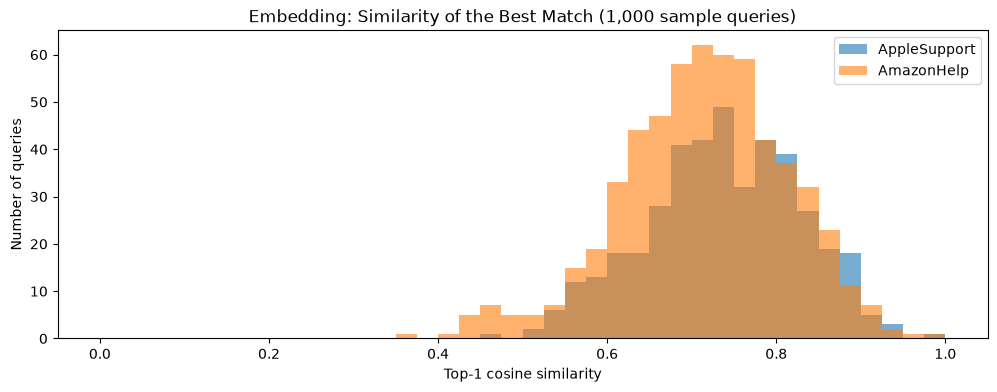

,25th Percentile,Median,75th Percentile
AppleSupport,0.681069,0.737897,0.804021
AmazonHelp,0.652070,0.719193,0.779103


In [15]:
# Same 1,000 sample queries as Section 4; one matrix product per brand instead of a loop over queries
start = time.time()
sample["emb_top1"] = 0.0
for brand in ["AppleSupport", "AmazonHelp"]:
    rows = (sample["brand"] == brand).to_numpy()
    brand_history = history_emb[(history["brand"] == brand).to_numpy()]
    sim = query_emb[sample.index[rows]] @ brand_history.T
    print(brand, "similarity table:", sim.shape)
    sample.loc[rows, "emb_top1"] = sim.max(axis=1)
print(f"Time for 1,000 queries: {time.time() - start:.2f} seconds")

# Histogram of the best score for each brand
plt.figure(figsize=(12, 4))
plt.hist(sample.loc[sample["brand"] == "AppleSupport", "emb_top1"], bins=np.linspace(0, 1, 41), alpha=0.6, label="AppleSupport")
plt.hist(sample.loc[sample["brand"] == "AmazonHelp", "emb_top1"], bins=np.linspace(0, 1, 41), alpha=0.6, label="AmazonHelp")
plt.xlabel("Top-1 cosine similarity")
plt.ylabel("Number of queries")
plt.title("Embedding: Similarity of the Best Match (1,000 sample queries)")
plt.legend()
plt.show()

# Median and quartiles of the best score with NumPy
brands = ["AppleSupport", "AmazonHelp"]
pd.DataFrame({
    "25th Percentile": [np.percentile(sample.loc[sample["brand"] == b, "emb_top1"], 25) for b in brands],
    "Median": [np.median(sample.loc[sample["brand"] == b, "emb_top1"]) for b in brands],
    "75th Percentile": [np.percentile(sample.loc[sample["brand"] == b, "emb_top1"], 75) for b in brands],
}, index=brands)

### 6. Evaluate

The data has no label that says which cases are similar, so we cannot compute accuracy directly. We compare the two methods in indirect ways, on the same 1,000 sample queries as before.

#### 6.1 How Different Are the Results?

First we check whether the two methods even return different cases. If they returned the same top 5, there would be nothing to compare.

- For each sample query, we get the top 5 history cases from TF-IDF and from the embedding method (same brand only).
- Then we count how many cases appear in both top-5 lists, from 0 (completely different) to 5 (identical).

In [16]:
# Top-5 history cases for each sample query: one row per query, one column per rank
k = 5
tfidf_top5 = np.zeros((len(sample), k), dtype=int)
emb_top5 = np.zeros((len(sample), k), dtype=int)

# TF-IDF: one query at a time
for n, i in enumerate(sample.index):
    scores = (history_tfidf @ query_tfidf[i].T).toarray().ravel()
    scores[(history["brand"] != query.loc[i, "brand"]).to_numpy()] = -1
    tfidf_top5[n] = np.argsort(scores)[::-1][:k]

# Embedding: one matrix product per brand, then sort each row from high to low
for brand in brands:
    rows = (sample["brand"] == brand).to_numpy()
    brand_index = np.where((history["brand"] == brand).to_numpy())[0]
    sim = query_emb[sample.index[rows]] @ history_emb[brand_index].T
    emb_top5[rows] = brand_index[np.argsort(sim, axis=1)[:, ::-1][:, :k]]

print("TF-IDF top-5 table:", tfidf_top5.shape)
print("Embedding top-5 table:", emb_top5.shape)

TF-IDF top-5 table: (1000, 5)
Embedding top-5 table: (1000, 5)


Average number of shared cases: 0.505


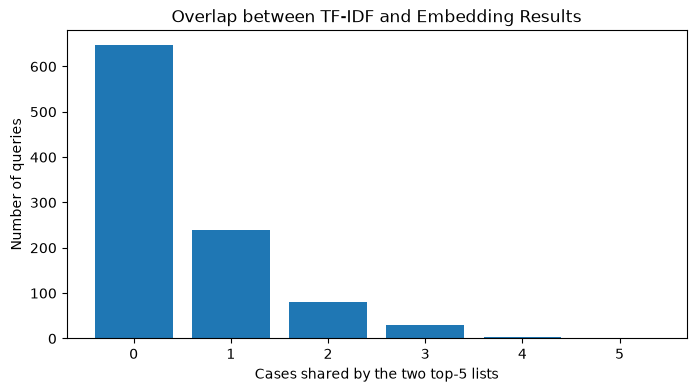

,Shared Cases,Number of Queries
0,0,647
1,1,239
2,2,81
3,3,29
4,4,3
5,5,1


In [17]:
# Count the cases that appear in both top-5 lists of each query
shared = np.array([len(np.intersect1d(tfidf_top5[n], emb_top5[n])) for n in range(len(sample))])
shared_counts = np.bincount(shared, minlength=k + 1)
print("Average number of shared cases:", shared.mean())

plt.figure(figsize=(8, 4))
plt.bar(np.arange(k + 1), shared_counts)
plt.xlabel("Cases shared by the two top-5 lists")
plt.ylabel("Number of queries")
plt.title("Overlap between TF-IDF and Embedding Results")
plt.show()
pd.DataFrame({"Shared Cases": np.arange(k + 1), "Number of Queries": shared_counts})

#### 6.2 Reply Similarity

Idea: if a matched history case is about the same kind of problem as the query, support probably answered both in a similar way. So for each query, we compare its real support reply with the replies of its top-5 matches. Higher similarity means better matches.

Two problems and how we handle them:

- **Template replies.** Many replies are templates such as "send us a dm". Any two cases can look similar because of them. So we add a random baseline: 5 random history cases from the same brand. A useful method must score clearly above random.
- **The judge can be biased.** Measuring reply similarity with embeddings may favor the embedding method, and measuring it with TF-IDF may favor TF-IDF. So we use both as judges. If one method wins under both judges, the result is more reliable.

Steps:

- Clean the replies: remove mentions, links and agent signatures like `^KH`.
- Judge 1 (TF-IDF): fit a new TF-IDF on the history replies.
- Judge 2 (embedding): encode only the replies we need (about 12,000, under a minute). `np.searchsorted` finds where each matched case sits in this smaller array, and broadcasting computes all 1,000 x 5 similarities at once.
- For each query we take the mean similarity over its 5 matches, then average over the 1,000 queries.

In [18]:
# Clean reply text: remove mentions, links and agent signatures like ^KH
history["reply_clean"] = history["reply_text"].str.replace(r"@\w+", " ", regex=True).str.replace(r"https?://\S+", " ", regex=True).str.replace(r"\^\w+", " ", regex=True)
history["reply_clean"] = history["reply_clean"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
sample["reply_clean"] = sample["reply_text"].str.replace(r"@\w+", " ", regex=True).str.replace(r"https?://\S+", " ", regex=True).str.replace(r"\^\w+", " ", regex=True)
sample["reply_clean"] = sample["reply_clean"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()

# How common are template replies?
print("History replies whose exact text is used more than once:", history["reply_clean"].duplicated(keep=False).sum(), "of", len(history))
pd.DataFrame({"Count": history["reply_clean"].value_counts().head(5)})

History replies whose exact text is used more than once: 19281 of 97331


,Count
reply_clean,
here’s what you can do to work around the issue until it’s fixed in a future software update:,4861
thanks for reaching out. we have a workaround for this here: dm us if you still need help.,575
thanks for reaching out. we're here to help. dm us so we can look into this further with you.,280
we're here to help. let's take this to dm so we can better assist you.,224
let's look into that. send us a dm and we'll go from there.,204


In [19]:
# Random baseline: 5 random history cases from the same brand for each query
rng = np.random.default_rng(1007)
random_top5 = np.zeros((len(sample), k), dtype=int)
for brand in brands:
    rows = (sample["brand"] == brand).to_numpy()
    brand_index = np.where((history["brand"] == brand).to_numpy())[0]
    random_top5[rows] = rng.choice(brand_index, size=(rows.sum(), k))
methods = {"Random": random_top5, "TF-IDF": tfidf_top5, "Embedding": emb_top5}

# Judge 1: TF-IDF similarity between the query's real reply and the replies of its 5 matches
reply_tfidf = TfidfVectorizer(stop_words="english", min_df=2)
history_reply_tfidf = reply_tfidf.fit_transform(history["reply_clean"])
sample_reply_tfidf = reply_tfidf.transform(sample["reply_clean"])
tfidf_judge = {}
for name, top5 in methods.items():
    tfidf_judge[name] = np.array([(history_reply_tfidf[top5[n]] @ sample_reply_tfidf[n].T).toarray().mean() for n in range(len(sample))])
    print("TF-IDF judge,", name, "mean reply similarity:", tfidf_judge[name].mean().round(3))

TF-IDF judge, Random mean reply similarity: 0.043
TF-IDF judge, TF-IDF mean reply similarity: 0.08
TF-IDF judge, Embedding mean reply similarity: 0.093


In [20]:
# Judge 2: embedding similarity; encode only the history replies that some method picked
needed = np.unique(np.concatenate([random_top5, tfidf_top5, emb_top5]))
model = SentenceTransformer("all-MiniLM-L6-v2")
needed_reply_emb = model.encode(history.loc[needed, "reply_clean"].tolist(), batch_size=256, show_progress_bar=True)
sample_reply_emb = model.encode(sample["reply_clean"].tolist(), batch_size=256, show_progress_bar=True)
needed_reply_emb = needed_reply_emb / np.linalg.norm(needed_reply_emb, axis=1, keepdims=True)
sample_reply_emb = sample_reply_emb / np.linalg.norm(sample_reply_emb, axis=1, keepdims=True)
print("Encoded history replies:", needed_reply_emb.shape)

emb_judge = {}
for name, top5 in methods.items():
    # Position of each matched case in the needed array, then a (1000, 5, 384) block of reply vectors
    matched = needed_reply_emb[np.searchsorted(needed, top5)]
    # Broadcasting: multiply each query reply with its 5 matched replies and sum over the 384 numbers
    sim = (matched * sample_reply_emb[:, np.newaxis, :]).sum(axis=2)
    emb_judge[name] = sim.mean(axis=1)
    print("Embedding judge,", name, "mean reply similarity:", emb_judge[name].mean().round(3))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/49 [00:00<?, ?it/s]

Batches:   0%|          | 0/4 [00:00<?, ?it/s]

Encoded history replies: (12539, 384)
Embedding judge, Random mean reply similarity: 0.293
Embedding judge, TF-IDF mean reply similarity: 0.369
Embedding judge, Embedding mean reply similarity: 0.398


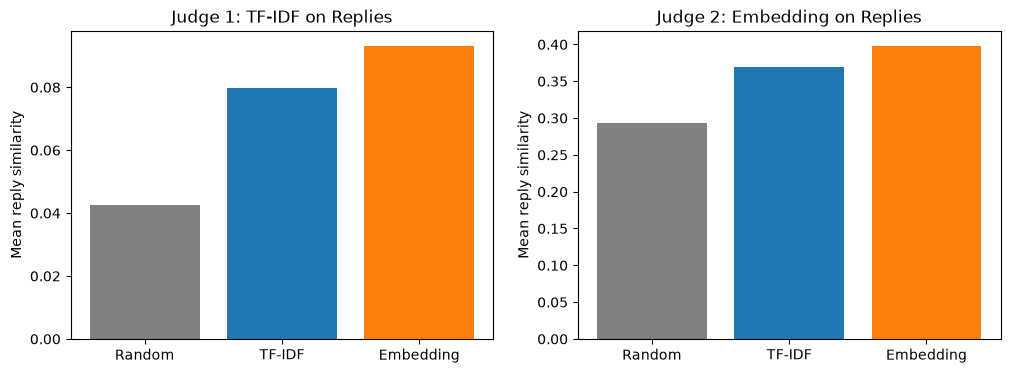

TF-IDF judge: Embedding wins 554 queries, TF-IDF wins 428 queries
Embedding judge: Embedding wins 600 queries, TF-IDF wins 399 queries


,TF-IDF Judge,Embedding Judge
Random,0.042543,0.293174
TF-IDF,0.079886,0.368697
Embedding,0.093247,0.398386


In [21]:
# Mean reply similarity of each method under each judge
summary = pd.DataFrame({
    "TF-IDF Judge": [tfidf_judge[name].mean() for name in methods],
    "Embedding Judge": [emb_judge[name].mean() for name in methods],
}, index=list(methods.keys()))

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.bar(summary.index, summary["TF-IDF Judge"], color=["gray", "tab:blue", "tab:orange"])
plt.ylabel("Mean reply similarity")
plt.title("Judge 1: TF-IDF on Replies")
plt.subplot(1, 2, 2)
plt.bar(summary.index, summary["Embedding Judge"], color=["gray", "tab:blue", "tab:orange"])
plt.ylabel("Mean reply similarity")
plt.title("Judge 2: Embedding on Replies")
plt.show()

# Query by query: how often does one method beat the other?
print("TF-IDF judge: Embedding wins", (tfidf_judge["Embedding"] > tfidf_judge["TF-IDF"]).sum(), "queries, TF-IDF wins", (tfidf_judge["TF-IDF"] > tfidf_judge["Embedding"]).sum(), "queries")
print("Embedding judge: Embedding wins", (emb_judge["Embedding"] > emb_judge["TF-IDF"]).sum(), "queries, TF-IDF wins", (emb_judge["TF-IDF"] > emb_judge["Embedding"]).sum(), "queries")
summary